# Demanda Elétrica dos Data Centers — EPE

Parte do projeto **O Impacto dos Data Centers na Demanda Elétrica Brasileira até 2036: Uma Análise com Dados do ONS, ANEEL e EPE**. A curadoria manual utiliza a versão de consulta pública do PDE 2036, no recorte de grandes cargas e data centers de grande porte, não exclusivamente IA. Valores de 2026 são estimativas/projeções e os de 2036 são projeções.


## 1. Carregamento dos Dados

Os valores foram transcritos manualmente da Figura 2-12 (p. 60) e da Tabela 2-4 (p. 59) do Relatório Síntese. O CSV registra documentos, URLs, perímetro e data da verificação.


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

ARQUIVO_EPE = (
    BASE_DIR / "data" / "reference" /
    "epe_pde2036.csv"
)

df_epe = pd.read_csv(ARQUIVO_EPE)

print("Dimensões:", df_epe.shape)
display(df_epe)


Dimensões: (4, 20)


,ano,indicador,valor_twh,natureza,fonte,url_fonte,cenario,versao,documento,url_documento,versao_documento,pagina_impressa,figura_tabela,definicao,perimetro,documento_complementar,url_documento_complementar,versao_documento_complementar,pagina_impressa_complementar,data_verificacao_referencias
0,2026,data_centers,3,estimativa,EPE - PDE 2036,https://www.epe.gov.br/pt/publicacoes-dados-ab...,referencia,consulta_publica_2026,"PDE 2036 - Relatório Síntese, consulta pública",https://www.epe.gov.br/sites-pt/publicacoes-da...,outubro/2026; arquivo rev3_2026-10-08,60,Figura 2-12,Consumo anual de eletricidade dos data centers...,Data centers de grande porte abrangidos pelo e...,PDE 2036 - Caderno de Demanda de Energia,https://www.epe.gov.br/sites-pt/publicacoes-da...,arquivo v1_2026-10-27,36,2026-11-10
1,2036,data_centers,30,projecao,EPE - PDE 2036,https://www.epe.gov.br/pt/publicacoes-dados-ab...,referencia,consulta_publica_2026,"PDE 2036 - Relatório Síntese, consulta pública",https://www.epe.gov.br/sites-pt/publicacoes-da...,outubro/2026; arquivo rev3_2026-10-08,60,Figura 2-12,Consumo anual de eletricidade dos data centers...,Data centers de grande porte abrangidos pelo e...,PDE 2036 - Caderno de Demanda de Energia,https://www.epe.gov.br/sites-pt/publicacoes-da...,arquivo v1_2026-10-27,36,2026-11-10
2,2026,eletricidade_total,702,projecao,EPE - PDE 2036,https://www.epe.gov.br/pt/publicacoes-dados-ab...,referencia,consulta_publica_2026,"PDE 2036 - Relatório Síntese, consulta pública",https://www.epe.gov.br/sites-pt/publicacoes-da...,outubro/2026; arquivo rev3_2026-10-08,59,Tabela 2-4,Consumo anual total de eletricidade no Brasil,"Classes de consumo, autoprodução não injetada ...",PDE 2036 - Caderno de Demanda de Energia,https://www.epe.gov.br/sites-pt/publicacoes-da...,arquivo v1_2026-10-27,11,2026-11-10
3,2036,eletricidade_total,979,projecao,EPE - PDE 2036,https://www.epe.gov.br/pt/publicacoes-dados-ab...,referencia,consulta_publica_2026,"PDE 2036 - Relatório Síntese, consulta pública",https://www.epe.gov.br/sites-pt/publicacoes-da...,outubro/2026; arquivo rev3_2026-10-08,59,Tabela 2-4,Consumo anual total de eletricidade no Brasil,"Classes de consumo, autoprodução não injetada ...",PDE 2036 - Caderno de Demanda de Energia,https://www.epe.gov.br/sites-pt/publicacoes-da...,arquivo v1_2026-10-27,11,2026-11-10


## 2. Indicadores de Crescimento e Participação
Cálculo do crescimento acumulado e da participação dos data centers.

In [2]:

# Transformar os indicadores em colunas
df_indicadores = df_epe.pivot(
    index="ano",
    columns="indicador",
    values="valor_twh"
).reset_index()

# Participação relativa dos data centers
df_indicadores["participacao_dc_pct"] = (
    df_indicadores["data_centers"] /
    df_indicadores["eletricidade_total"] * 100
)

# Crescimento acumulado de cada indicador
crescimento_dc = (
    df_indicadores.loc[
        df_indicadores["ano"] == 2036,
        "data_centers"
    ].iloc[0] /
    df_indicadores.loc[
        df_indicadores["ano"] == 2026,
        "data_centers"
    ].iloc[0] - 1
) * 100

crescimento_total = (
    df_indicadores.loc[
        df_indicadores["ano"] == 2036,
        "eletricidade_total"
    ].iloc[0] /
    df_indicadores.loc[
        df_indicadores["ano"] == 2026,
        "eletricidade_total"
    ].iloc[0] - 1
) * 100

display(df_indicadores)

print(
    f"Crescimento dos data centers: "
    f"{crescimento_dc:.2f}%"
)

print(
    f"Crescimento da eletricidade total: "
    f"{crescimento_total:.2f}%"
)


indicador,ano,data_centers,eletricidade_total,participacao_dc_pct
0,2026,3,702,0.427350
1,2036,30,979,3.064351


Crescimento dos data centers: 900.00%
Crescimento da eletricidade total: 39.46%


## 3. Visualização 05 - Demanda dos Data Centers
Comparação entre a estimativa de 2026 e a projeção de 2036.

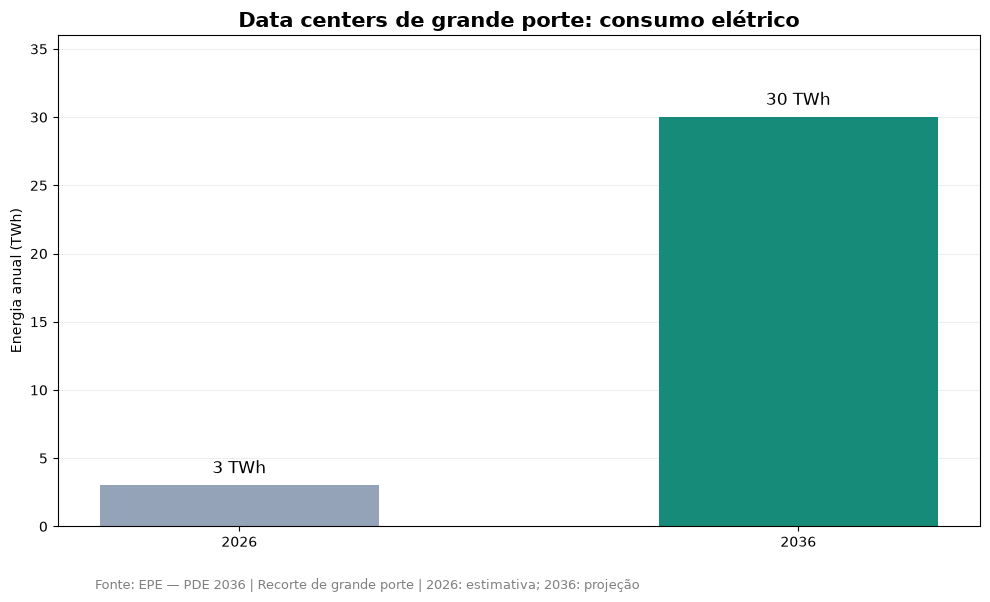

In [3]:

# Selecionar dados dos data centers
df_dc = df_epe[
    df_epe["indicador"] == "data_centers"
].sort_values("ano")

fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.bar(
    df_dc["ano"].astype(str),
    df_dc["valor_twh"],
    color=["#94A3B8", "#168B79"],
    width=0.5
)

ax.bar_label(
    barras,
    labels=[
        f"{valor:.0f} TWh"
        for valor in df_dc["valor_twh"]
    ],
    padding=6,
    fontsize=12
)

ax.set_title(
    "Data centers de grande porte: consumo elétrico",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("Energia anual (TWh)")
ax.set_xlabel("")
ax.set_ylim(0, 36)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.1, 0.01,
    "Fonte: EPE — PDE 2036 | "
    "Recorte de grande porte | 2026: estimativa; 2036: projeção",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

PASTA_IMAGENS = BASE_DIR / "images"
PASTA_IMAGENS.mkdir(exist_ok=True)

plt.savefig(
    PASTA_IMAGENS / "05_demanda_datacenters.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 4. Visualização 06 — Participação dos Data Centers

O denominador é o consumo total de eletricidade da EPE, inclusive autoprodução não injetada; 3,06% não é participação calculada sobre a carga do SIN.


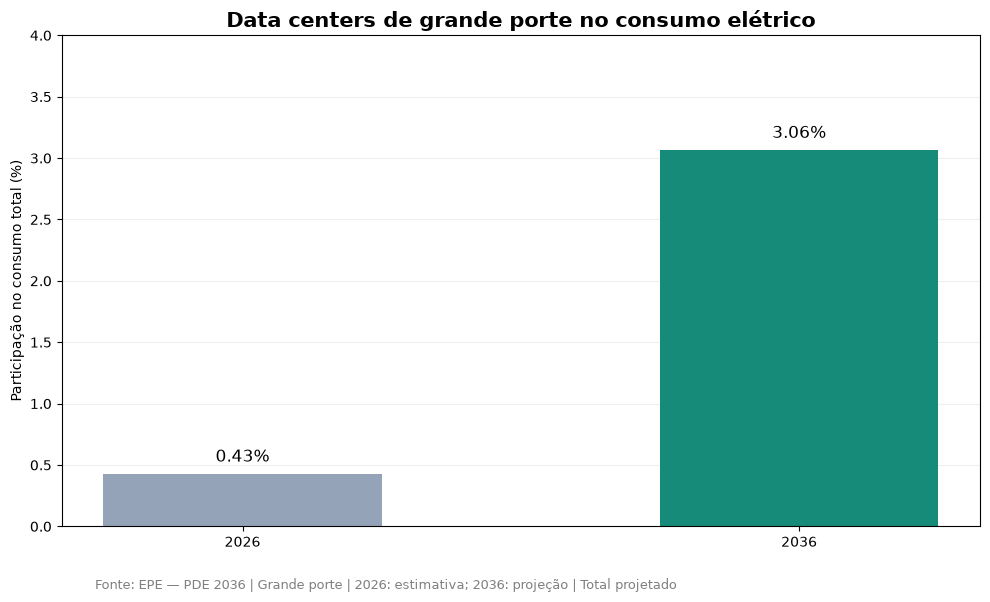

In [4]:

fig, ax = plt.subplots(figsize=(10, 6))

anos = df_indicadores["ano"].astype(str)
participacoes = df_indicadores["participacao_dc_pct"]

barras = ax.bar(
    anos,
    participacoes,
    color=["#94A3B8", "#168B79"],
    width=0.5
)

ax.bar_label(
    barras,
    labels=[
        f"{valor:.2f}%"
        for valor in participacoes
    ],
    padding=6,
    fontsize=12
)

ax.set_title(
    "Data centers de grande porte no consumo elétrico",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("Participação no consumo total (%)")
ax.set_ylim(0, 4)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.1, 0.01,
    "Fonte: EPE — PDE 2036 | "
    "Grande porte | 2026: estimativa; 2036: projeção | Total projetado",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.savefig(
    PASTA_IMAGENS / "06_participacao_datacenters.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 5. Visualização 07 - Participação no Crescimento Projetado
Contribuição dos data centers para a expansão do consumo elétrico entre 2026 e 2036.

Crescimento data centers: 27.0 TWh
Crescimento total: 277.0 TWh
Participação: 9.75%


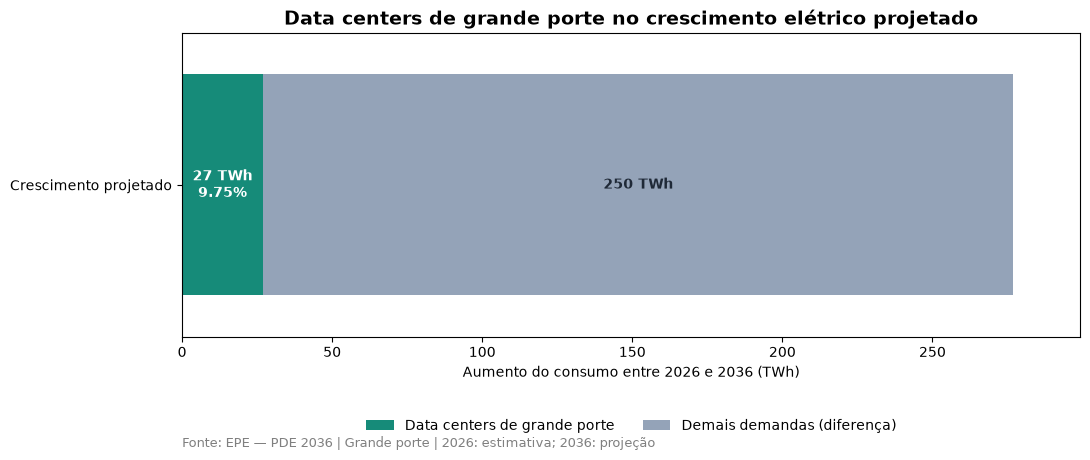

In [5]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Localizar projeto
BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

# Carregar dados oficiais registrados da EPE
arquivo = BASE_DIR / "data" / "reference" / "epe_pde2036.csv"
df_epe = pd.read_csv(arquivo)

# Organizar dados
dados = df_epe.pivot(
    index="ano",
    columns="indicador",
    values="valor_twh"
)

# Calcular diferenças entre 2026 e 2036
crescimento_dc = (
    dados.loc[2036, "data_centers"]
    - dados.loc[2026, "data_centers"]
)

crescimento_total = (
    dados.loc[2036, "eletricidade_total"]
    - dados.loc[2026, "eletricidade_total"]
)

crescimento_outros = crescimento_total - crescimento_dc

participacao = crescimento_dc / crescimento_total * 100

print(f"Crescimento data centers: {crescimento_dc:.1f} TWh")
print(f"Crescimento total: {crescimento_total:.1f} TWh")
print(f"Participação: {participacao:.2f}%")

# Criar gráfico
fig, ax = plt.subplots(figsize=(11, 5))

ax.barh(
    ["Crescimento projetado"],
    [crescimento_dc],
    color="#168B79",
    label="Data centers de grande porte"
)

ax.barh(
    ["Crescimento projetado"],
    [crescimento_outros],
    left=[crescimento_dc],
    color="#94A3B8",
    label="Demais demandas (diferença)"
)

# Rótulos
ax.text(
    crescimento_dc / 2,
    0,
    f"{crescimento_dc:.0f} TWh\n{participacao:.2f}%",
    ha="center",
    va="center",
    color="white",
    fontweight="bold"
)

ax.text(
    crescimento_dc + crescimento_outros / 2,
    0,
    f"{crescimento_outros:.0f} TWh",
    ha="center",
    va="center",
    color="#1F2937",
    fontweight="bold"
)

ax.set_title(
    "Data centers de grande porte no crescimento elétrico projetado",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Aumento do consumo entre 2026 e 2036 (TWh)")
ax.set_xlim(0, crescimento_total * 1.08)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.23),
          ncol=2, frameon=False)

ax.text(
    0,
    -0.95,
    "Fonte: EPE — PDE 2036 | Grande porte | 2026: estimativa; 2036: projeção",
    fontsize=9,
    color="gray"
)

ax.set_ylim(-0.55, 0.55)

plt.tight_layout()

pasta_imagens = BASE_DIR / "images"
pasta_imagens.mkdir(exist_ok=True)

plt.savefig(
    pasta_imagens / "07_participacao_crescimento.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 6. Visualização 08 — Comparação de Escalas ONS/EPE

Compara a carga média do SIN de janeiro a outubro de 2026 com potências médias equivalentes anuais dos data centers. A série ONS inclui componentes estimados e tem perímetro diferente do consumo total da EPE. A conversão civil usa 8.760 horas em 2026 e 8.784 em 2036. A EPE também apresenta uma conversão convencional de 8.760 horas; ela é apropriada para reproduzir a convenção da própria publicação, enquanto o ano civil é usado aqui.


SIN jan–out/2026: 80,800 MW médios
Data centers 2026: 342 MW médios
Data centers 2036: 3,415 MW médios


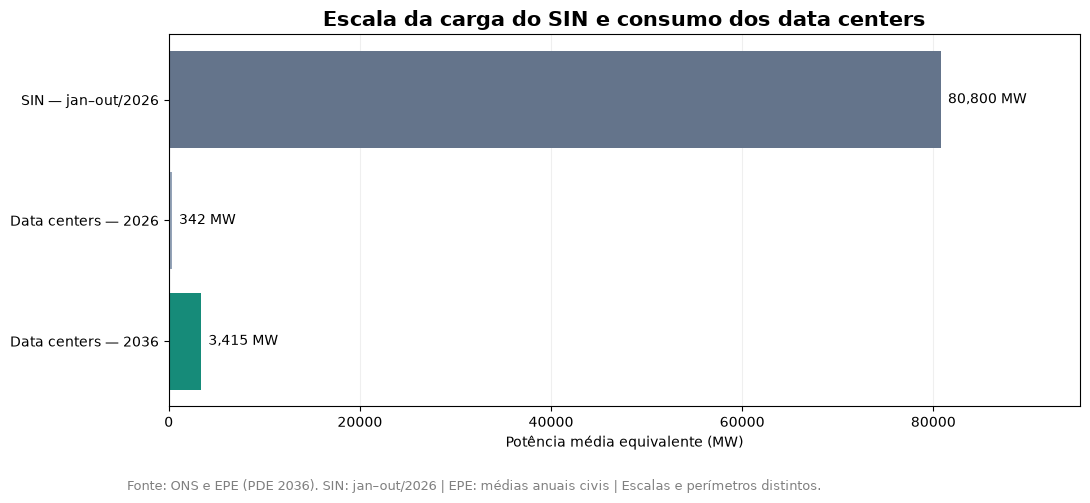

In [6]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from calendar import isleap

BASE_DIR = Path.cwd()
if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

# Dados históricos do ONS
df_ons = pd.read_parquet(
    BASE_DIR / "data/gold/carga_mensal.parquet"
)

# Dados de referência da EPE
df_epe = pd.read_csv(
    BASE_DIR / "data/reference/epe_pde2036.csv"
)

# SIN: janeiro a outubro de 2026
base_ons = df_ons[
    (df_ons["ano"] == 2026)
    & (df_ons["mes"] <= 10)
    & (df_ons["mes_completo"])
].copy()

assert base_ons.groupby("mes")[
    "id_subsistema"
].nunique().eq(4).all()

assert base_ons["mes"].nunique() == 10

energia_sin_mwh = base_ons["energia_mwh"].sum()

# Somar dias sem repetir os 4 subsistemas
dias = (
    base_ons.groupby("mes")["dias_observados"]
    .first().sum()
)

carga_sin = energia_sin_mwh / (dias * 24)

# Demanda anual de data centers convertida em MW médios
dc = df_epe[
    df_epe["indicador"] == "data_centers"
].set_index("ano")["valor_twh"]

dc_2026 = dc.loc[2026] * 1_000_000 / (8784 if isleap(2026) else 8760)
dc_2036 = dc.loc[2036] * 1_000_000 / (8784 if isleap(2036) else 8760)

print(f"SIN jan–out/2026: {carga_sin:,.0f} MW médios")
print(f"Data centers 2026: {dc_2026:,.0f} MW médios")
print(f"Data centers 2036: {dc_2036:,.0f} MW médios")

# Visualização
categorias = [
    "SIN — jan–out/2026",
    "Data centers — 2026",
    "Data centers — 2036"
]

valores = [carga_sin, dc_2026, dc_2036]

fig, ax = plt.subplots(figsize=(11, 5))

barras = ax.barh(
    categorias,
    valores,
    color=["#64748B", "#94A3B8", "#168B79"]
)

ax.invert_yaxis()

ax.bar_label(
    barras,
    labels=[f"{v:,.0f} MW" for v in valores],
    padding=5
)

ax.set_xlim(0, max(valores) * 1.18)

ax.set_title(
    "Escala da carga do SIN e consumo dos data centers",
    fontweight="bold",
    fontsize=15
)

ax.set_xlabel("Potência média equivalente (MW)")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.12, 0.01,
    "Fonte: ONS e EPE (PDE 2036). "
    "SIN: jan–out/2026 | EPE: médias anuais civis | Escalas e perímetros distintos.",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

pasta = BASE_DIR / "images"
pasta.mkdir(exist_ok=True)

plt.savefig(
    pasta / "08_comparacao_ons_epe.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
